In [ ]:
import pandas as pd
import numpy as np

data = {
    "id": [1, 2, 3, 4, 5, 6],
    "title": [
        "Breaking: NASA finds water on Mars!",
        "Donald Trump resigns from presidency",
        None,   # missing title
        "COVID-19 vaccine proven safe by WHO",
        "Aliens landed in New York City yesterday!",
        "Stock markets reach record highs"
    ],
    "text": [
        "NASA confirms the discovery of liquid water on the surface of Mars.",
        "Breaking news suggests Donald Trump has resigned, but it's not confirmed.",
        "Scientists have found cure for cancer, says unknown website.",
        None,  # missing content
        "Aliens are real and they have landed in New York, sources claim.",
        "The stock market has seen growth after the latest tech boom."
    ],
    "label": [1, 0, 1, 0, 1, 0]   # 1 = Fake, 0 = Real
}

df = pd.DataFrame(data)
df


,id,title,text,label
0,1,Breaking: NASA finds water on Mars!,NASA confirms the discovery of liquid water on...,1
1,2,Donald Trump resigns from presidency,Breaking news suggests Donald Trump has resign...,0
2,3,None,"Scientists have found cure for cancer, says un...",1
3,4,COVID-19 vaccine proven safe by WHO,None,0
4,5,Aliens landed in New York City yesterday!,Aliens are real and they have landed in New Yo...,1
5,6,Stock markets reach record highs,The stock market has seen growth after the lat...,0


## Check Missing Values

In [ ]:
print(df.isnull().sum())

id       0
title    1
text     1
label    0
dtype: int64


## Handle Missing Values

Options:

Drop rows with too many missing values.

Fill missing with "Unknown" or "No Text".

In [ ]:
df['title'].fillna("No Title", inplace=True)
df['text'].fillna("No Text", inplace=True)

/tmp/ipython-input-2663909596.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['title'].fillna("No Title", inplace=True)
/tmp/ipython-input-2663909596.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 

## Text Cleaning

We usually clean text by:

Lowercasing

Removing punctuation, numbers

Removing stopwords (“the”, “is”, etc.)

Lemmatization/Stemming

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words = set(stopwords.words("english"))

def clean_text(text):
    # lowercase
    text = text.lower()
    # remove punctuation & numbers
    text = re.sub(r'[^a-z\s]', '', text)
    # remove stopwords
    text = " ".join([word for word in text.split() if word not in stop_words])
    return text

df['clean_text'] = df['text'].apply(clean_text)
df[['text', 'clean_text']]


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,text,clean_text
0,NASA confirms the discovery of liquid water on...,nasa confirms discovery liquid water surface mars
1,Breaking news suggests Donald Trump has resign...,breaking news suggests donald trump resigned c...
2,"Scientists have found cure for cancer, says un...",scientists found cure cancer says unknown website
3,No Text,text
4,Aliens are real and they have landed in New Yo...,aliens real landed new york sources claim
5,The stock market has seen growth after the lat...,stock market seen growth latest tech boom


## Quick Analysis

Word counts, most frequent words, class distribution.

In [ ]:
# Class balance
print(df['label'].value_counts())

label
1    3
0    3
Name: count, dtype: int64


In [ ]:
# Word counts
df['word_count'] = df['clean_text'].apply(lambda x: len(x.split()))
print(df[['clean_text','word_count']])

                                          clean_text  word_count
0  nasa confirms discovery liquid water surface mars           7
1  breaking news suggests donald trump resigned c...           7
2  scientists found cure cancer says unknown website           7
3                                               text           1
4          aliens real landed new york sources claim           7
5          stock market seen growth latest tech boom           7


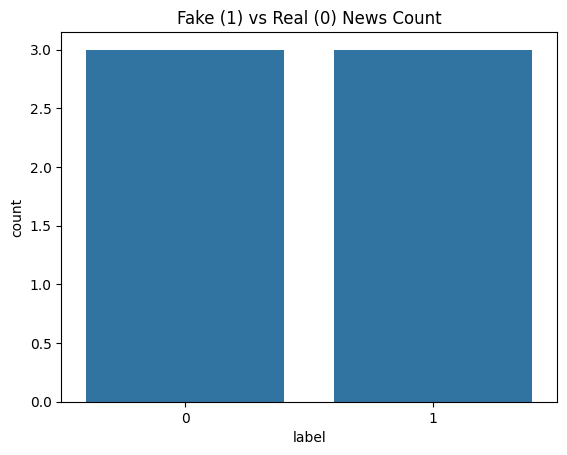

In [ ]:
# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='label', data=df)
plt.title("Fake (1) vs Real (0) News Count")
plt.show()